# Object detection — train and evaluate

Training is one call; the interesting part is *reading what comes out*. This notebook trains, plots the learning curves, evaluates on the test split, and shows you how to interpret each number.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/detection/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("detection", cfg)
print("task:", "detection", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: detection | data: data/demo/detection | outputs: outputs/detection_quick


## The configuration
Everything tunable is in one YAML file. These are the sections that matter:

In [3]:
import yaml

for section in ('data', 'model', 'train'):
    print(section + ':')
    for line in yaml.safe_dump(cfg[section], sort_keys=False).splitlines():
        print('  ' + line)

data:
  root: data/demo/detection
  images_dir: images
  annotations: annotations.json
  image_size: 128
  batch_size: 8
  num_workers: 0
  split:
    train: 0.7
    val: 0.15
    test: 0.15
  augment:
    hflip: true
    vflip: false
    color_jitter: 0.1
model:
  arch: fasterrcnn_resnet18_fpn
  pretrained: false
  pretrained_detector: false
  roi_samples_per_image: 32
train:
  epochs: 15
  lr: 0.001
  weight_decay: 0.0001
  grad_clip: 10.0
  amp: true
  early_stopping_patience: 0


## What are we about to train?

In [4]:
from cvkit.utils import count_parameters
from cvkit.detection import build_coco_loaders
from tasks.detection.model import build_model

classes = build_coco_loaders(cfg)["classes"]
model = build_model(cfg, {"classes": classes})
p = count_parameters(model)
print(f"arch {cfg['model']['arch']} | pretrained backbone {cfg['model']['pretrained']} | {len(classes)} classes (+1 background)")
print(f"{p['total']:,} parameters, {p['trainable']:,} trainable ({p['trainable_pct']:.0f}%)")
del model

arch fasterrcnn_resnet18_fpn | pretrained backbone False | 3 classes (+1 background)
28,293,731 parameters, 28,293,731 trainable (100%)


## Train
Watch the `val` numbers: they are what picks the best epoch.

In [5]:
from tasks.detection.train import train

result = train(cfg)
print('\nbest epoch:', result['best_epoch'], '|', {k: round(v, 4) for k, v in result['best_metrics'].items()})

arch: fasterrcnn_resnet18_fpn | classes (3): ['circle', 'square', 'triangle']


device: cpu | parameters: 28,293,731 total, 28,293,731 trainable (100.0%)


epoch   1/15 | train_loss 4.6367 | val map=0.004 map50=0.014 map75=0.000 | 18.6s  <- best


epoch   2/15 | train_loss 1.2690 | val map=0.172 map50=0.471 map75=0.037 | 19.0s  <- best


epoch   3/15 | train_loss 1.0232 | val map=0.258 map50=0.570 map75=0.244 | 19.9s  <- best


...

epoch  11/15 | train_loss 0.3367 | val map=0.734 map50=1.000 map75=0.904 | 21.8s  <- best


epoch  12/15 | train_loss 0.2773 | val map=0.822 map50=0.997 map75=0.982 | 22.1s  <- best


epoch  13/15 | train_loss 0.2448 | val map=0.836 map50=1.000 map75=1.000 | 22.4s  <- best


epoch  14/15 | train_loss 0.2228 | val map=0.849 map50=0.999 map75=0.999 | 22.8s  <- best


epoch  15/15 | train_loss 0.1809 | val map=0.872 map50=0.999 map75=0.999 | 22.7s  <- best
best val map = 0.8724 (epoch 15) -> outputs/detection_quick/checkpoints/best.pt

best epoch: 15 | {'map': 0.8724, 'map50': 0.9991, 'map75': 0.9991}


## Learning curves
Detection has no validation *loss*; the right-hand panels are validation **mAP** (higher is better). The left panel is the training loss. Expect mAP to climb in steps. **Gap widening** between train and val → overfitting (more augmentation, fewer epochs, smaller model). **Both flat and poor** → underfitting (train longer, raise the learning rate, unfreeze the backbone). **Val bouncing hard** → learning rate too high, or the val split is small. Remember the quick preset trains for only a few epochs, so expect curves still on their way up.

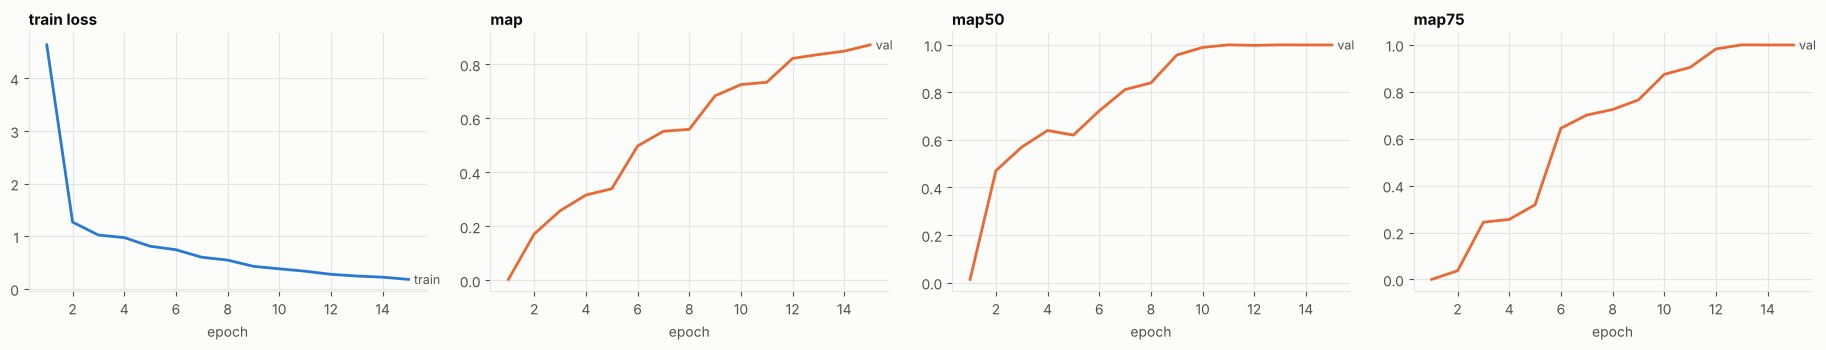

In [6]:
from cvkit.viz import plot_history

_ = plot_history(Path(cfg['output']['dir']) / 'history.csv')

## Evaluate on the test split
Val chose the checkpoint; the **test split** was untouched until now, so it is the honest number. One rule: look at test results, *don't tune on them* — the moment you tweak settings to chase the test score, it stops measuring generalisation.

In [7]:
from tasks.detection.evaluate import evaluate

metrics = evaluate(cfg)

mAP@[.5:.95] 0.906 | mAP@.5 1.000 | mAP@.75 1.000 (36 test images)
at score >= 0.5: precision 0.908 | recall 1.000 (TP 79, FP 8, FN 0)
  AP@.5 circle           1.000
  AP@.5 square           1.000
  AP@.5 triangle         1.000
reports -> outputs/detection_quick/reports


ap_per_class.png


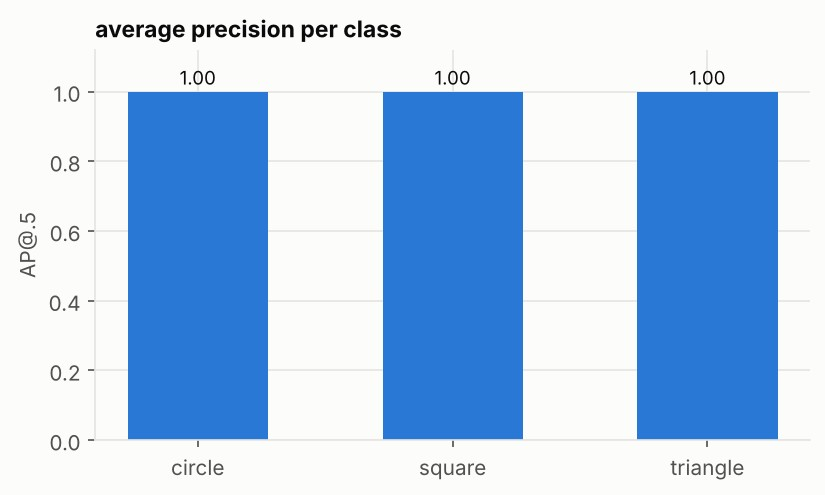

predictions.png


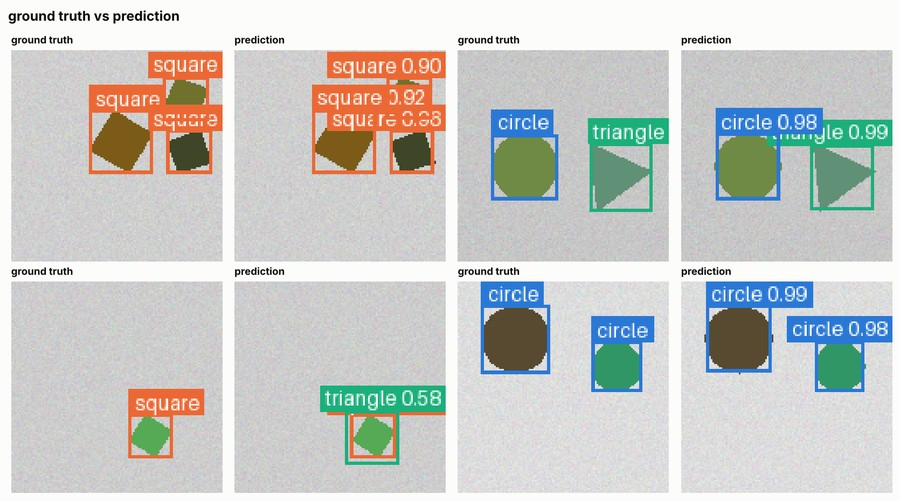

worst_images.png


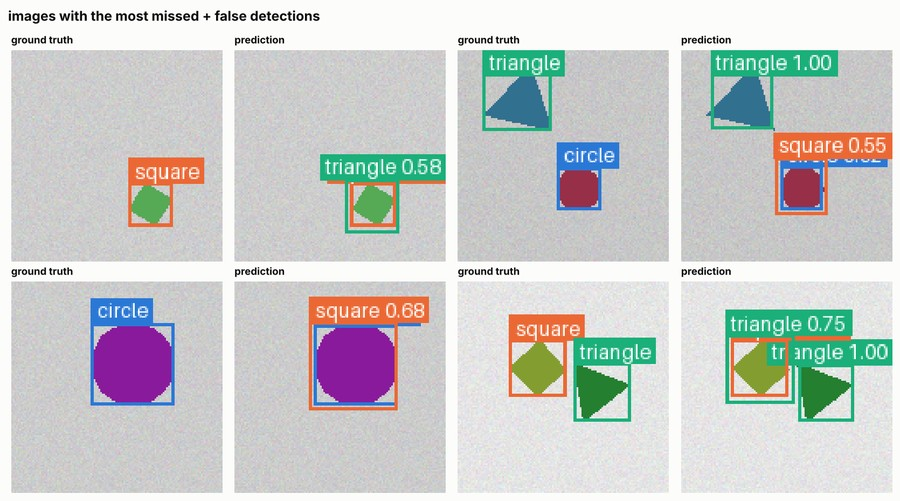

In [8]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['ap_per_class.png', 'predictions.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

## How to read these results
* **IoU** (intersection over union) — how much a predicted box overlaps a true box: shared area ÷ combined area. 1 = identical.
* **mAP@.5** — a detection is *correct* if it has IoU ≥ 0.5 with an unmatched true box of the same class. Generous: roughly "found the right object".
* **mAP@[.5:.95]** — the same, averaged over IoU thresholds 0.5, 0.55, … 0.95. Strict: rewards *tight* boxes. This one picked the best epoch. A big gap between mAP@.5 and mAP@[.5:.95] means the model finds objects but boxes them loosely.
* **Precision / recall at the score threshold** — what a user sees: precision = of the boxes shown, how many were real; recall = of the real objects, how many got a box. Raise `eval.score_threshold` for fewer false boxes, lower it for fewer misses.
* **AP per class** — which class is hard? Often the rare or the small one.
* **Worst images** — missed object (recall problem), phantom box (precision problem), or right object wrong class? Duplicate boxes of different classes on one object are common early on.

## Experiments worth running
Each one is a one-line change. Re-run the training cell with a different config and compare the best val numbers (change `cfg` like this, then re-run from *Train*):

```python
cfg['model']['arch'] = 'resnet34'     # or any key, same as --set model.arch=resnet34
```

1. `data.image_size = 192` — does a larger input help small objects, and what does it cost in time?
2. `train.epochs` ×2 — the mAP curve is probably still climbing
3. `data.augment.hflip = False` — what does the flip contribute?
4. `model.arch = 'fasterrcnn_mobilenet_v3_large_320_fpn'` — a lighter, faster detector
5. On real data, `model.pretrained = True` (and, for resnet50/mobilenet archs, `model.pretrained_detector = True` to start from COCO) usually matters more than any other change

Change **one thing at a time**, keep the seed, and write down what you changed — otherwise you can't tell what helped.

Next: **[03_predict_and_deploy](03_predict_and_deploy.ipynb)**.